# Data Visualization — Complete Revision Notebook (Pandas / Matplotlib / Seaborn)

A topic-wise reference for turning data into plots — the core toolkit for Exploratory
Data Analysis (EDA), which is a required step before building any ML model. We build a
small synthetic "sales" dataset below so the notebook runs standalone.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
n = 200
products = ['Choco Bar', 'Truffle Box', 'Milk Bar', 'Dark Bar', 'Choco Cookies']
df = pd.DataFrame({
    'Product': np.random.choice(products, n, p=[0.35, 0.15, 0.2, 0.15, 0.15]),
    'Boxes_Shipped': np.random.poisson(30, n),
    'Amount': np.round(np.random.normal(500, 150, n), 2).clip(50),
    'Rating': np.clip(np.random.normal(4, 0.7, n), 1, 5),
})
df.loc[df.sample(frac=0.05, random_state=1).index, 'Boxes_Shipped'] = np.nan  # a few missing values
df.head()

,Product,Boxes_Shipped,Amount,Rating
0,Truffle Box,32.0,255.87,4.012904
1,Choco Cookies,24.0,507.21,4.243307
2,Dark Bar,32.0,538.96,3.622168
3,Milk Bar,22.0,364.35,3.455187
4,Choco Bar,NaN,595.79,4.137092


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Product        200 non-null    str    
 1   Boxes_Shipped  190 non-null    float64
 2   Amount         200 non-null    float64
 3   Rating         200 non-null    float64
dtypes: float64(3), str(1)
memory usage: 6.4 KB


## 1. Bar Charts — Categorical Data (Counts)

Use a bar chart when the x-axis holds **categories** and the y-axis holds a **count or
aggregate**. `Series.plot(kind='bar')` is the fastest way to visualize `value_counts()`
output — the very first EDA chart for any categorical column.

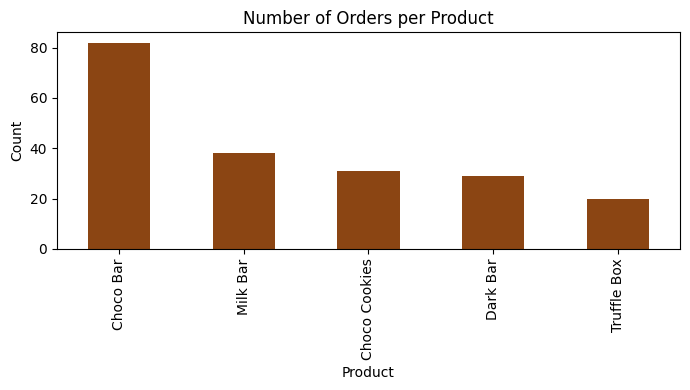

In [3]:
df['Product'].value_counts().plot(kind='bar', figsize=(7, 4), color='saddlebrown')
plt.title('Number of Orders per Product')
plt.xlabel('Product')
plt.ylabel('Count')
plt.tight_layout()
plt.show()

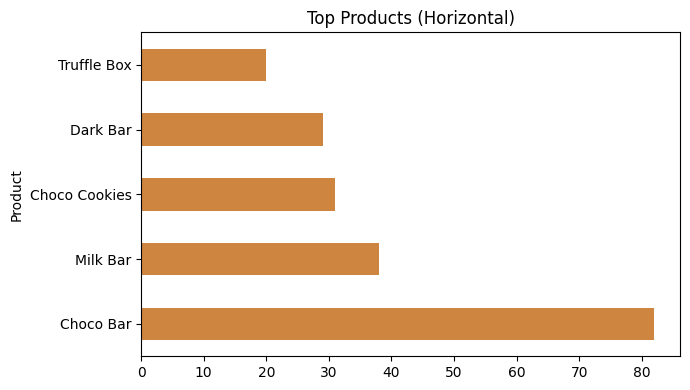

In [4]:
# Horizontal bar -> better when category labels are long
df['Product'].value_counts().head().plot(kind='barh', figsize=(7, 4), color='peru')
plt.title('Top Products (Horizontal)')
plt.tight_layout()
plt.show()

## 2. Pie Chart — Proportions

Good for showing **share of a whole** across a small number of categories. Avoid pie
charts when there are many categories — a bar chart reads better.

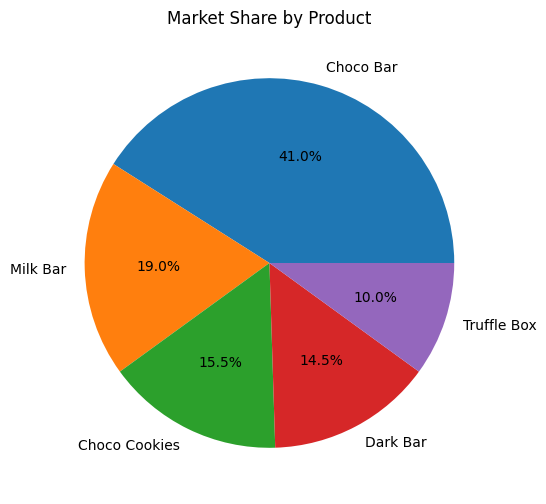

In [5]:
df['Product'].value_counts().plot(kind='pie', autopct='%1.1f%%', figsize=(6, 6))
plt.title('Market Share by Product')
plt.ylabel('')
plt.show()

## 3. Histogram — Distribution of Continuous Data

A histogram bins a continuous numeric variable and shows how frequently values fall
into each bin. This is the standard way to check a feature's **distribution** (skew,
outliers, normality) before modeling.

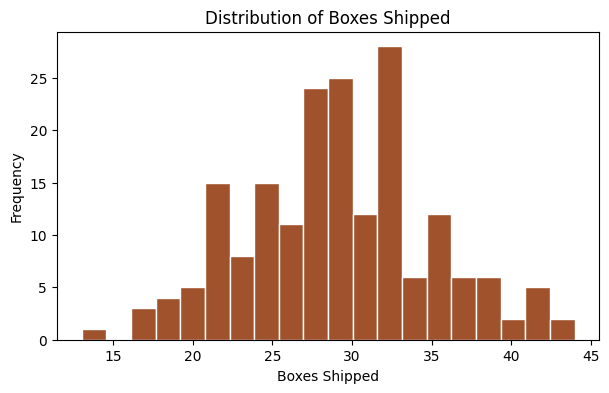

In [6]:
df['Boxes_Shipped'].plot(kind='hist', bins=20, figsize=(7, 4), color='sienna', edgecolor='white')
plt.title('Distribution of Boxes Shipped')
plt.xlabel('Boxes Shipped')
plt.show()

## 4. Scatter Plot — Relationship Between Two Numeric Variables

Scatter plots reveal correlation/trend between two continuous variables — essential
before fitting a regression model or checking for multicollinearity.

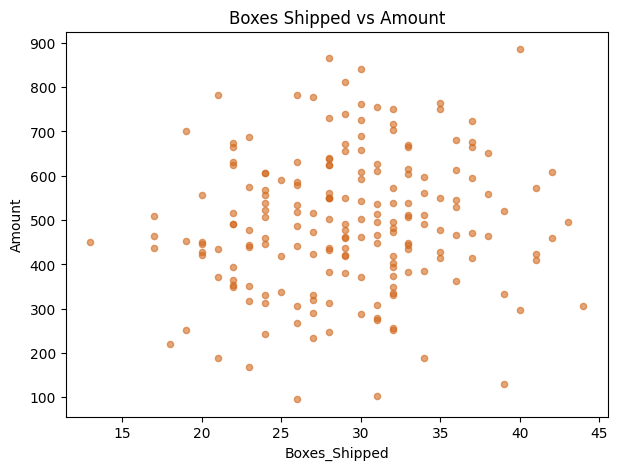

In [7]:
df.plot(kind='scatter', x='Boxes_Shipped', y='Amount', figsize=(7, 5), alpha=0.6, color='chocolate')
plt.title('Boxes Shipped vs Amount')
plt.show()

## 5. Line Plot — Trends Over an Ordered Axis — *added*

Line plots are the default choice for **time series** or any ordered sequence (e.g.
sales over days, loss curve over training epochs).

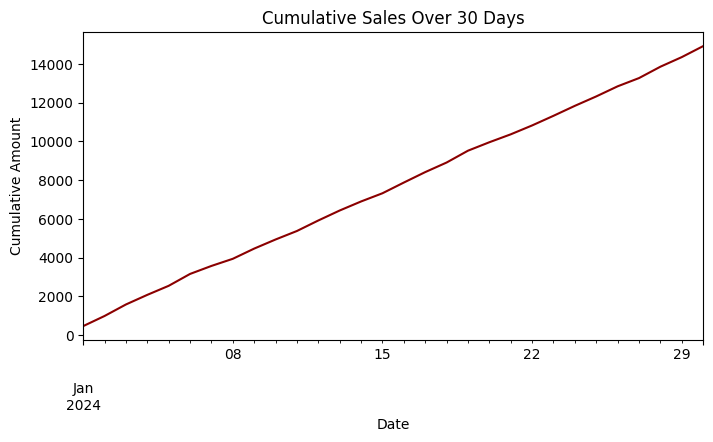

In [8]:
daily = pd.Series(np.random.normal(500, 60, 30).cumsum(), index=pd.date_range('2024-01-01', periods=30))
daily.plot(kind='line', figsize=(8, 4), color='darkred')
plt.title('Cumulative Sales Over 30 Days')
plt.xlabel('Date')
plt.ylabel('Cumulative Amount')
plt.show()

## 6. Box Plot — Spread and Outliers — *added*

A box plot summarizes a distribution using quartiles (median, IQR, whiskers) and
flags outliers as individual points — much more precise than a histogram for spotting
outliers, a key EDA task before training a model.

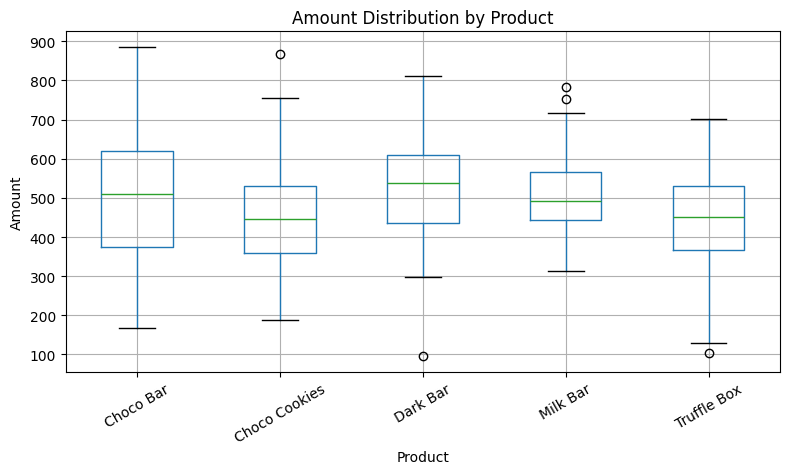

In [9]:
df.boxplot(column='Amount', by='Product', figsize=(8, 5), rot=30)
plt.title('Amount Distribution by Product')
plt.suptitle('')  # remove default pandas subtitle
plt.ylabel('Amount')
plt.tight_layout()
plt.show()

## 7. Matplotlib Fundamentals — *added*

Pandas `.plot()` is a convenient shortcut, but real control comes from Matplotlib
directly: `plt.figure`, `plt.subplots`, labels, legends, and multi-panel figures. These
are used to build clean, presentation-ready EDA reports and to plot training curves
(loss/accuracy per epoch) when training models.

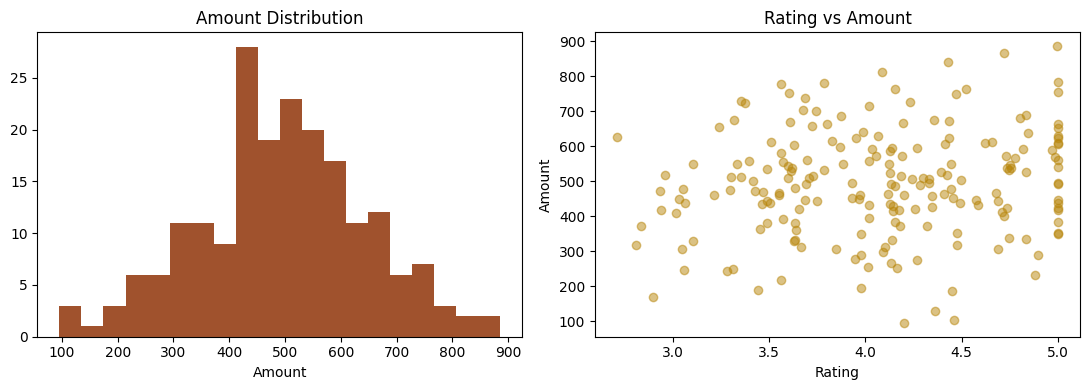

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(df['Amount'], bins=20, color='sienna')
axes[0].set_title('Amount Distribution')
axes[0].set_xlabel('Amount')

axes[1].scatter(df['Rating'], df['Amount'], alpha=0.5, color='darkgoldenrod')
axes[1].set_title('Rating vs Amount')
axes[1].set_xlabel('Rating')
axes[1].set_ylabel('Amount')

plt.tight_layout()
plt.show()

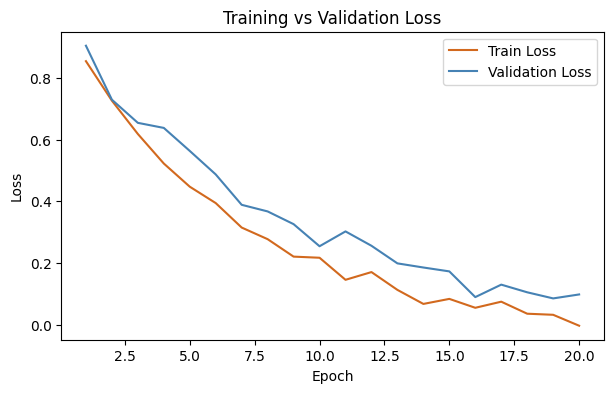

In [11]:
# Multiple lines on one axis + legend -> classic ML "training curve" style plot
epochs = np.arange(1, 21)
train_loss = np.exp(-epochs / 6) + np.random.normal(0, 0.02, 20)
val_loss = np.exp(-epochs / 7) + 0.05 + np.random.normal(0, 0.03, 20)

plt.figure(figsize=(7, 4))
plt.plot(epochs, train_loss, label='Train Loss', color='chocolate')
plt.plot(epochs, val_loss, label='Validation Loss', color='steelblue')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')
plt.legend()
plt.show()

## 8. Seaborn for Statistical EDA — *added, crucial for ML/AI*

Seaborn builds on Matplotlib and is the standard library for statistical EDA before
modeling — especially **correlation heatmaps** and **pairplots**, which quickly reveal
which features are related to each other or to the target variable.

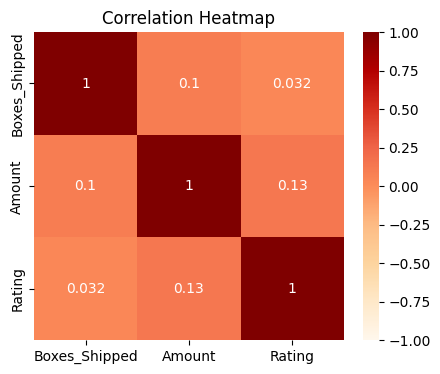

In [12]:
import seaborn as sns

numeric_df = df[['Boxes_Shipped', 'Amount', 'Rating']]

plt.figure(figsize=(5, 4))
sns.heatmap(numeric_df.corr(), annot=True, cmap='OrRd', vmin=-1, vmax=1)
plt.title('Correlation Heatmap')
plt.show()

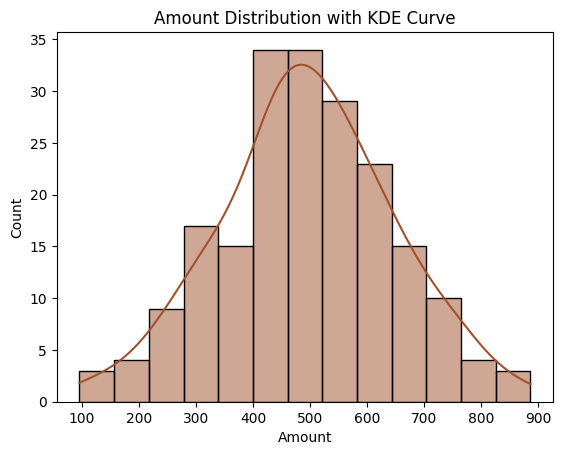

In [13]:
sns.histplot(data=df, x='Amount', kde=True, color='sienna')
plt.title('Amount Distribution with KDE Curve')
plt.show()

/tmp/ipykernel_524/2790577985.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='Product', y='Amount', palette='YlOrBr')


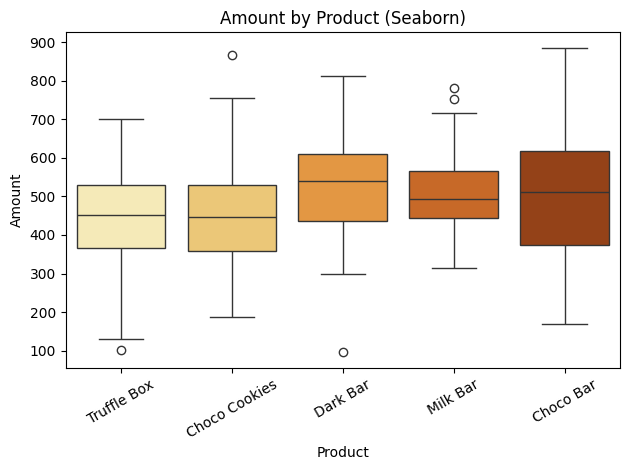

In [14]:
sns.boxplot(data=df, x='Product', y='Amount', palette='YlOrBr')
plt.xticks(rotation=30)
plt.title('Amount by Product (Seaborn)')
plt.tight_layout()
plt.show()

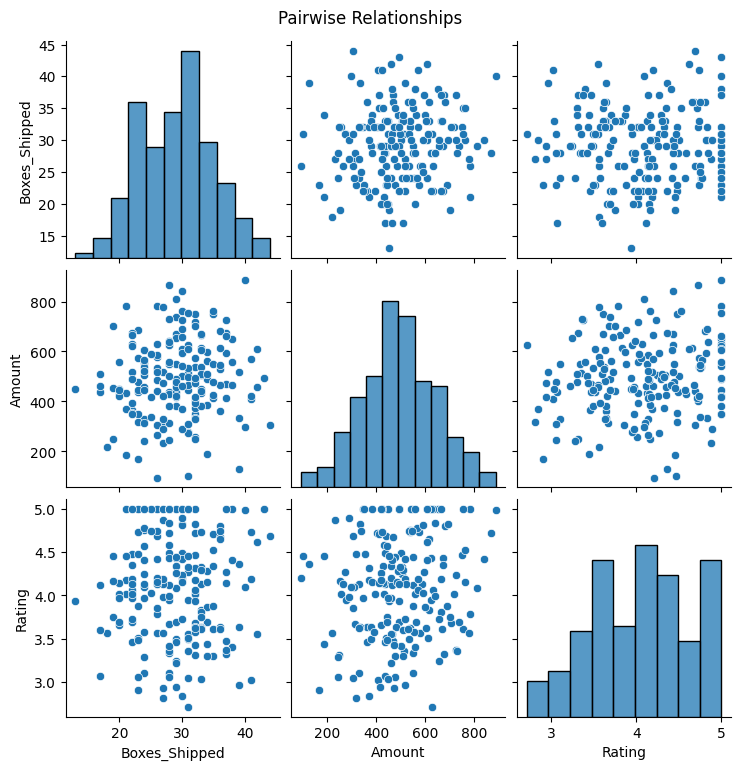

In [15]:
sns.pairplot(df[['Boxes_Shipped', 'Amount', 'Rating']].dropna())
plt.suptitle('Pairwise Relationships', y=1.02)
plt.show()

## 9. Visualizing Missing Data — *added, crucial for ML/AI*

Before imputing or dropping missing values, it helps to *see* where they are. A quick
heatmap of `isnull()` shows missing-data patterns at a glance.

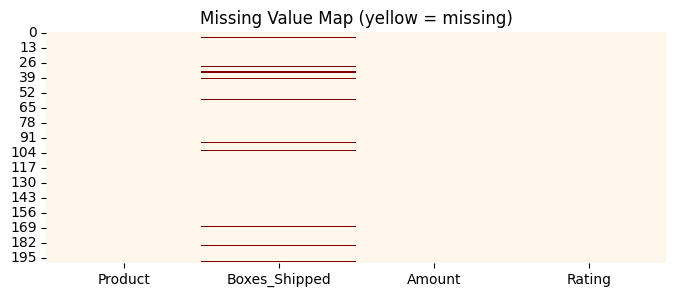

Product           0
Boxes_Shipped    10
Amount            0
Rating            0
dtype: int64


In [16]:
plt.figure(figsize=(8, 3))
sns.heatmap(df.isnull(), cbar=False, cmap='OrRd')
plt.title('Missing Value Map (yellow = missing)')
plt.show()

print(df.isnull().sum())

## 10. Saving Figures — *added*

`plt.savefig()` exports a chart to a file — useful for embedding plots in reports,
dashboards, or model-evaluation write-ups.

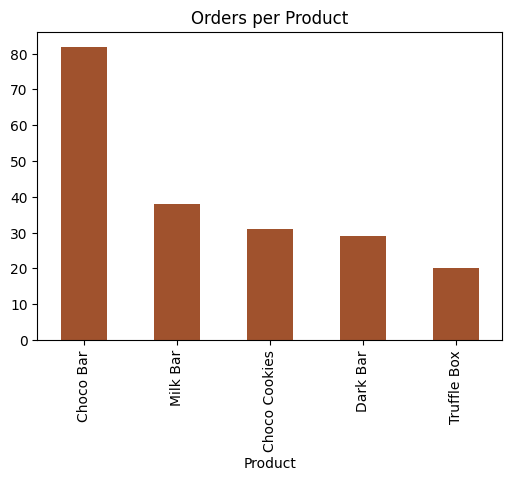

Saved to /tmp/orders_per_product.png


In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
df['Product'].value_counts().plot(kind='bar', ax=ax, color='sienna')
ax.set_title('Orders per Product')
fig.savefig('/tmp/orders_per_product.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved to /tmp/orders_per_product.png')

## Summary — Original Notes vs What Was Added

**Covered from your original notebook:** bar & horizontal bar charts from
`value_counts()`, pie chart, histogram, scatter plot.

**Added because they're essential for ML/AI EDA and were missing:**
1. Line plots — the standard chart for time series / training curves
2. Box plots — precise outlier and spread detection (Pandas + Seaborn)
3. Matplotlib fundamentals — `subplots`, multi-panel figures, legends, styled
   train-vs-validation loss curves (the exact plot used to monitor model training)
4. Seaborn — correlation heatmaps, `histplot` with KDE, `pairplot` for pairwise feature
   relationships — the fastest way to understand a dataset before modeling
5. Missing-value heatmap — visual sanity check before imputing/dropping data
6. Saving figures with `plt.savefig()` for reports and dashboards